# Bias dependence at high displacement field (Supplementary Fig. S53; Fig. R6 of the response letter)

File 2035. Output: `figs/bias_wc.pdf`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../utils"))  # repo utils/ (vendored sweep + shared helpers)
from fft_sup_imports import *
%matplotlib inline
update_rc_params('paper')

['/home/aaron/Fermiology-and-the-cCSC/figs/bias_wc.pdf',
 '/home/aaron/Fermiology-and-the-cCSC/figs/bias_wc.png']

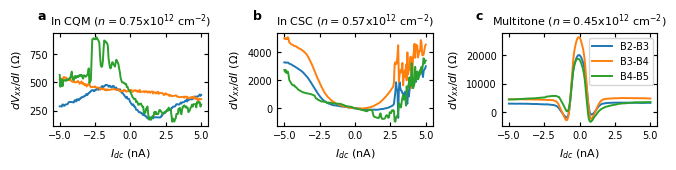

In [2]:
# Fig. R6 with panel order reversed: CQM (a), CSC (b), multitone (c)
files = [2035]
n_targets = [0.75, 0.57, 0.45]
labels = ['B2-B3', 'B3-B4', 'B4-B5']
titles = ['In CQM', 'In CSC', 'Multitone']

scale = 0.5
fig, axs = plt.subplots(1, 3, figsize=(3*4.5*scale, 3.5*scale))

for ind in [1, 2, 3]:
    for file in files:
        data = sl.pload(file_path, file)
        vtg = data['ys'][0]
        vbg = data['ys'][1]
        nvec, _ = calculate_n_D(vtg, vbg, dtg=17.25, dbg=25.5)
        idcvec = data['xs'][0]*10

        I = data['sr830_4_X']
        Vxx = data[f'sr830_{ind}_X']
        zs = Vxx/I

        for i, n0 in enumerate(n_targets):
            i_n = np.argmin(np.abs(nvec - n0))
            axs[i].plot(idcvec, zs[i_n], label=labels[ind-1])

for i, ax in enumerate(axs):
    if i == 2:
        ax.legend()
    ax.set_title(titles[i] + f' ($n=${n_targets[i]}x10$^{{12}}$ cm$^{{-2}}$)')
    ax.set_xlabel(r'$I_{dc}$ (nA)')
    ax.set_ylabel(r'$dV_{xx}/dI$ ($\Omega$)')

fig.text(0.06, 0.88, 'a', fontweight='bold')
fig.text(0.38, 0.88, 'b', fontweight='bold')
fig.text(0.71, 0.88, 'c', fontweight='bold')

plt.tight_layout()
save_fig(fig, "bias_wc")